# Adversarial Examples on Logistic Regression
Logistic regression is the simplest model to which the linear explanation of adversarial examples applies **exactly**, not just locally.

We implement logistic regression here using PyTorch.

The notebook has five parts:

**Part 1 — Binary logistic regression on MNIST**

**Part 2 — Multiclass (softmax) logistic regression on MNIST**

**Part 3 — Binary Logistic Regression on STL-10**

**Part 4 — Multiclass (softmax) logistic regression on STL-10**

**Part 5 — Summary**

References: Szegedy et al. (2014), *Intriguing Properties of Neural Networks*;
Goodfellow et al. (2015), *Explaining and Harnessing Adversarial Examples*.

# 0. Setup
We rely on helper modules for most underlying functionalities: data loading, reproducibility, training, model initialization, attack implementations.

We import these helper modules as well as libraries needed for training and plotting.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from advrobust.utils import SEED, device
from advrobust.data import (
    train_ds, test_ds,
    train_bin, test_bin, train_loader_bin, test_loader_bin,
    train_loader, test_loader,
    make_binary_split, get_binary_val_split,
)
from advrobust.models import BinaryLogReg, MulticlassLogReg
from advrobust.train import train, bce
from advrobust.evaluate import evaluate_clean, evaluate_fgsm, evaluate_noise
from advrobust.attacks import fgsm_attack, gaussian_noise_attack, random_sign_attack

Matplotlib is building the font cache; this may take a moment.
100.0%
100.0%
100.0%
100.0%


## 1. Reproducibility
Seeds are fixed inside `data.py` at import time. Importing `data.py` improves a reproducible data split.
## 2. Loading Data: MNIST
MNIST is downloaded and loaded inside `data.py`, which
also builds the binary and full multiclass train/test splits and
DataLoaders (`train_bin`, `test_bin`, `train_loader_bin`, `test_loader_bin`, `train_loader`, `test_loader`) used throughout this notebook.     

STL_10 is a large dataset, so we ensure it's not loaded when `data.py` is being imported but only when it's needed.

### 2.1 Data Exploration

MNIST is a standard dataset used for learning, so we only do some quick exploration/consistency check.

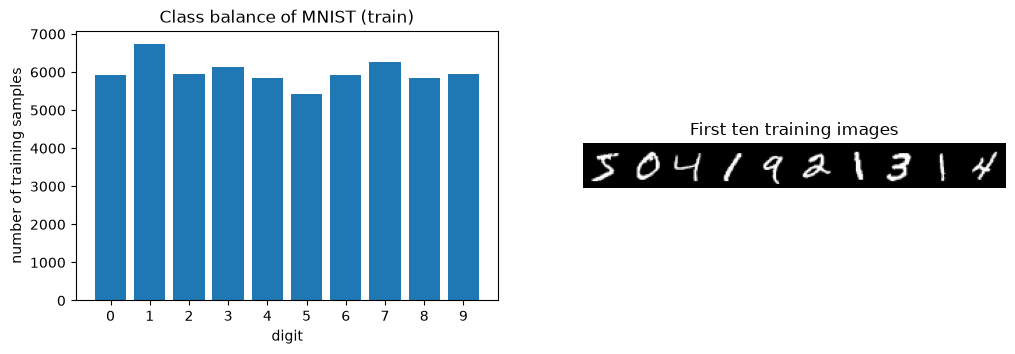

In [2]:
from torchvision.utils import make_grid

# Class balance
train_labels = train_ds.targets # all labels in dataset
counts = torch.bincount(train_labels, minlength=10) # count occurrences

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

axes[0].bar(range(10), counts.numpy())
axes[0].set_xlabel("digit")
axes[0].set_ylabel("number of training samples")
axes[0].set_title("Class balance of MNIST (train)")
axes[0].set_xticks(range(10))

# Show some examples
# train_ds converted images to tensors (via the transform) for training,
# so even just to display them here, we have to convert them back
# We use make_grid, torchvision's utility for arranging a batch of
# image tensors into a single grid (see documentation).

examples = torch.stack([train_ds[i][0] for i in range(10)]) # (10, 1, 28, 28)
grid = make_grid(examples, nrow=10, padding=2) # we need a "Tensor of shape (B x C x H x W)" - https://docs.pytorch.org/vision/main/generated/torchvision.utils.make_grid.html
axes[1].imshow(grid.permute(1, 2, 0), cmap="gray")
axes[1].set_title("First ten training images")
axes[1].axis("off"); # semi-colon prevents from printing out the output

The classes are roughly balanced; each digit appears around 6000 times, so plain accuracy is a meaningful metric, we do not need class weighting.

---

# Part 1 - Binary logistic regression on MNIST
We start with restricting MNIST to digits **3** and **8** (two digits that could be confused) and relabel them as 0 and 1.
| Original digit | Mapped label |
|:---------------:|:------------:|
| 3               | 0            |
| 8               | 1            |

## Quick regularization strength search: can be skipped

In [3]:
# Check of strengths
train_sub_loader, val_sub_loader = get_binary_val_split()

alphas = [1e-5, 1e-4, 1e-3, 1e-2]

for a in alphas:
  m_l1 = train(BinaryLogReg(), train_sub_loader, binary=True, epochs=15, lr=0.05, reg_type='l1', reg_strength=a)
  m_l2 = train(BinaryLogReg(), train_sub_loader, binary=True, epochs=15, lr=0.05, reg_type='l2', reg_strength=a)

  l1_acc = evaluate_clean(m_l1, val_sub_loader, binary=True)
  l2_acc = evaluate_clean(m_l2, val_sub_loader, binary=True)
  print("alpha:", a)
  print("l1 val acc:", round(l1_acc, 4))
  print("l2 val acc:", round(l2_acc, 4))

epoch 1 | loss: 0.1903 | train acc: 0.9264
epoch 5 | loss: 0.1052 | train acc: 0.9689
epoch 10 | loss: 0.0983 | train acc: 0.9711
epoch 15 | loss: 0.0953 | train acc: 0.973
epoch 1 | loss: 0.1867 | train acc: 0.9319
epoch 5 | loss: 0.1044 | train acc: 0.9693
epoch 10 | loss: 0.1003 | train acc: 0.9696
epoch 15 | loss: 0.0947 | train acc: 0.972
alpha: 1e-05
l1 val acc: 0.9683
l2 val acc: 0.9705
epoch 1 | loss: 0.1913 | train acc: 0.933
epoch 5 | loss: 0.1124 | train acc: 0.9687
epoch 10 | loss: 0.107 | train acc: 0.9702
epoch 15 | loss: 0.1048 | train acc: 0.9709
epoch 1 | loss: 0.1869 | train acc: 0.9321
epoch 5 | loss: 0.1053 | train acc: 0.9681
epoch 10 | loss: 0.0986 | train acc: 0.9714
epoch 15 | loss: 0.0971 | train acc: 0.9713
alpha: 0.0001
l1 val acc: 0.9699
l2 val acc: 0.9699
epoch 1 | loss: 0.2252 | train acc: 0.927
epoch 5 | loss: 0.1609 | train acc: 0.9645
epoch 10 | loss: 0.1562 | train acc: 0.9666
epoch 15 | loss: 0.1557 | train acc: 0.9677
epoch 1 | loss: 0.1901 | train a

# 1.1 Training models with no regularization, with $\ell^1$ and  $\ell^2$ regularization.

We train **three** binary models here:

1. No regularization
2. $\ell^2$ (ridge)
3. $\ell^1$ (lasso)

We predict that the lasso penalty should make the model more robust to adversarial examples.

We use the `BinaryLogReg` model and a training pipeline imported from `models.py` and `train.py` respectively.

We choose universal regularization strength to make adversarial comparisons fair. We base our choice on the quick search below:

In [4]:
print("Training unregularized model:")
model_none = train(BinaryLogReg(), train_loader_bin, binary=True, lr=0.05, reg_type=None)

print("")

print("Training l2-regularized model:")
model_l2 = train(BinaryLogReg(), train_loader_bin, binary=True, lr=0.05, reg_type='l2', reg_strength=0.0001)

print("")

print("Training l1-regularized model:")
model_l1 = train(BinaryLogReg(), train_loader_bin, binary=True, lr=0.05, reg_type='l1', reg_strength=0.0001)

print("")

print("Test accuracy (none):", round(evaluate_clean(model_none, test_loader_bin, binary=True), 4))
print("Test accuracy (l2):", round(evaluate_clean(model_l2, test_loader_bin, binary=True), 4))
print("Test accuracy (l1):", round(evaluate_clean(model_l1, test_loader_bin, binary=True), 4))

Training unregularized model:
epoch 1 | loss: 0.1783 | train acc: 0.9346
epoch 5 | loss: 0.1022 | train acc: 0.9699
epoch 10 | loss: 0.0959 | train acc: 0.9718
epoch 15 | loss: 0.0927 | train acc: 0.972

Training l2-regularized model:
epoch 1 | loss: 0.1734 | train acc: 0.9354
epoch 5 | loss: 0.103 | train acc: 0.9686
epoch 10 | loss: 0.0965 | train acc: 0.9725
epoch 15 | loss: 0.0957 | train acc: 0.9729

Training l1-regularized model:
epoch 1 | loss: 0.1836 | train acc: 0.9347
epoch 5 | loss: 0.1102 | train acc: 0.9688
epoch 10 | loss: 0.1053 | train acc: 0.97
epoch 15 | loss: 0.1033 | train acc: 0.972

Test accuracy (none): 0.9677
Test accuracy (l2): 0.9662
Test accuracy (l1): 0.9677


We got really nice results for all models, regularization did not affect accuracy.

## 1.2 Looking at the weight vectors
We visualize weights. Red/blue regions show pixels that push predictions towards 8 or towards 3.

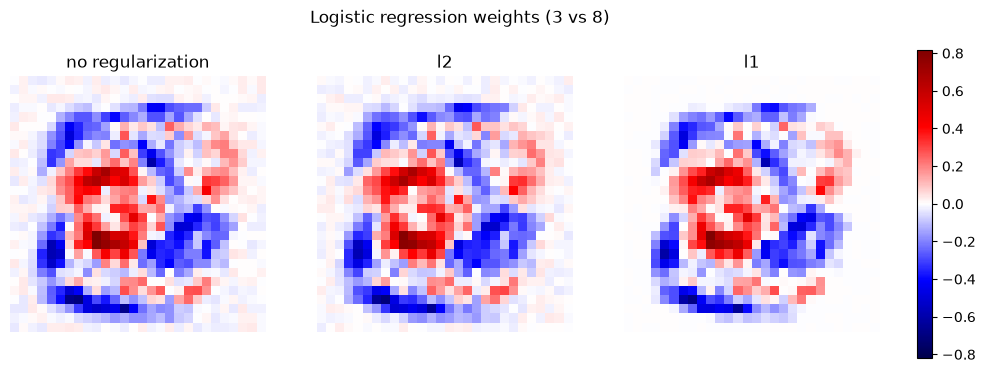

In [5]:
binary_models = [("no regularization", model_none), ("l2", model_l2), ("l1", model_l1)] # save results

weights = []
for name, m in binary_models:
    w = m.linear.weight.detach().cpu().view(28, 28)
    weights.append(w)

vmax = max(w.abs().max().item() for w in weights)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (name, m), w in zip(axes, binary_models, weights):
    im = ax.imshow(w, cmap="seismic", vmin=-vmax, vmax=vmax)

    ax.set_title(name)
    ax.axis("off")

fig.colorbar(im, ax=axes, fraction=0.025, pad=0.04)

plt.suptitle("Logistic regression weights (3 vs 8)")
plt.show()

In [6]:
import pandas as pd
# AI-assisted: ChatGPT was used to help format the model norm results into a pandas DataFrame;
# results and calculations are verified by the author.
rows = []

for name, m in binary_models:
    w = m.linear.weight.detach().cpu().flatten()

    rows.append({
        "model": name,
        "L1 norm": round(w.abs().sum().item(), 2),
        "L2 norm": round(w.norm().item(), 2),
        "Inf norm": round(w.abs().max().item(), 4),
        "zeros": (w.abs() < 1e-6).sum().item()
    })

pd.DataFrame(rows)

,model,L1 norm,L2 norm,Inf norm,zeros
0,no regularization,103.71,5.69,0.8181,0
1,l2,102.21,5.59,0.7911,0
2,l1,84.59,5.22,0.8092,42


What we see:
1. The $\ell^1$-regularized weights are **sparse**: many pixels are exactly or close to zero;
2. The $\ell^1$-regularized model has the lowest $\|w\|_1$, which should mean a more robust model (to adversarial examples).

## 1.3 FGSM on the binary models
We now attack all three models with FGSM at increasing $\varepsilon$ and plot accuracy-vs-$\varepsilon$ curves.


In [7]:
EPSILONS_MNIST = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.25]
# Accuracy for different epsilons
results_bin = {}
for name, m in binary_models:
  accs = []
  for eps in EPSILONS_MNIST:
        if eps == 0.0:
            acc = evaluate_clean(m, test_loader_bin, binary=True) # clean accuracy
        else:
            acc = evaluate_fgsm(m, test_loader_bin, eps, binary=True)
        accs.append(acc)
  results_bin[name] = accs
  print(name, ":", *[round(a, 3) for a in accs])




no regularization : 0.968 0.935 0.779 0.387 0.118 0.018 0.001
l2 : 0.966 0.928 0.778 0.398 0.149 0.03 0.001
l1 : 0.968 0.941 0.83 0.483 0.197 0.043 0.005


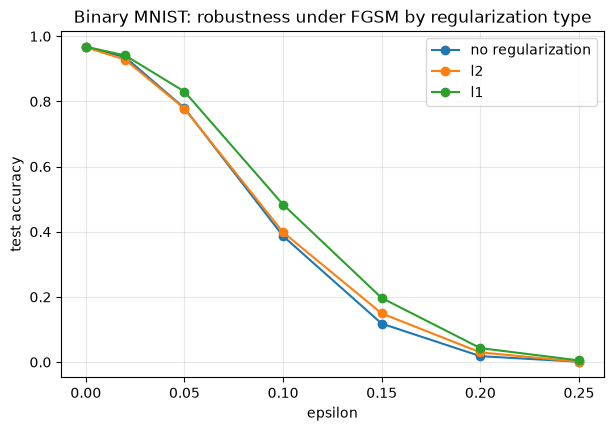

In [8]:
# plot accuracy vs attack strength
plt.figure(figsize=(7, 4.5))
for name, accs in results_bin.items():
    plt.plot(EPSILONS_MNIST, accs, marker="o", label=name)
plt.xlabel("epsilon")
plt.ylabel("test accuracy")
plt.title("Binary MNIST: robustness under FGSM by regularization type")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

We can see that accuracy degrades significantly.

## 1.4 Comparison with random noise
We compare FGSM to two noise implementations all bounded by $\varepsilon$:

- **Gaussian noise**: the noise is centered around 0, so pixels can either increase or decrease. Its standard deviation is set to ε/3, which means most pixel changes are much smaller than ε.
- **Random sign noise**: every pixel moved by exactly $\pm\varepsilon$ (random sign).

In [9]:
gaussian_accs = []

for eps in EPSILONS_MNIST:
    if eps == 0:
        acc = evaluate_clean(model_none, test_loader_bin, binary=True)
    else:
        acc = evaluate_noise(model_none, test_loader_bin, eps, gaussian_noise_attack, binary=True)
    gaussian_accs.append(acc)

results_bin["gaussian noise"] = gaussian_accs
print("gaussian noise:", *[round(a, 3) for a in gaussian_accs])


random_sign_accs = []

for eps in EPSILONS_MNIST:
    if eps == 0:
        acc = evaluate_clean(model_none, test_loader_bin, binary=True)
    else:
        acc = evaluate_noise(model_none, test_loader_bin, eps, random_sign_attack, binary=True)
    random_sign_accs.append(acc)

results_bin["random sign noise"] = random_sign_accs
print("random sign noise:", *[round(a, 3) for a in random_sign_accs])

gaussian noise: 0.968 0.968 0.967 0.966 0.966 0.966 0.962
random sign noise: 0.968 0.966 0.963 0.963 0.949 0.922 0.895


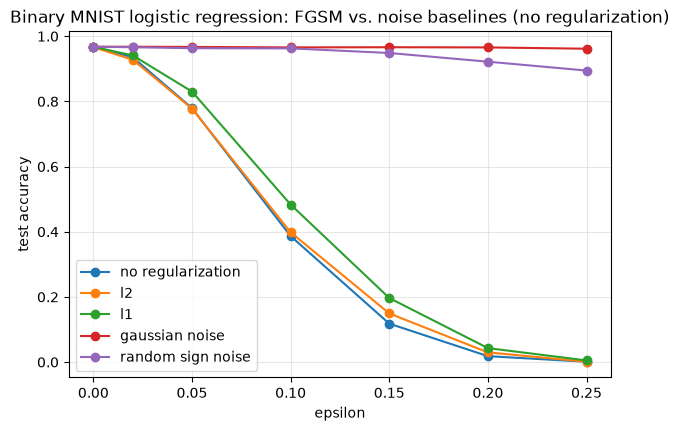

In [10]:
plt.figure(figsize=(7, 4.5))
for name, accs in results_bin.items():
    plt.plot(EPSILONS_MNIST, accs, marker="o", label=name)
plt.xlabel("epsilon")
plt.ylabel("test accuracy")
plt.title("Binary MNIST logistic regression: FGSM vs. noise baselines (no regularization)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Noise does not degrade the model nearly as much as FGSM does.

### Comparing the theoretical max change to actual change
$\varepsilon\|w\|_1$ is the theoretical maximum that we are able to compute directly. We check how close FGSM gets to that maximum as well as our noise implementations.

In [11]:
def compare_output_change(model, x, y, epsilon, noise_fns):

    # theoretical maximum change
    w = model.linear.weight.detach().flatten()
    theoretical_max = epsilon * w.abs().sum().item()

    x = x.to(device)
    y = y.to(device).float()

    # model output before sigmoid
    clean_output = model.linear(x.view(x.size(0), -1)).squeeze(-1)

    # FGSM
    x_fgsm = fgsm_attack(model, x, y, epsilon, bce)
    fgsm_output = model.linear(x_fgsm.view(x_fgsm.size(0), -1)).squeeze(-1)

    fgsm_change = (fgsm_output - clean_output).abs().mean().item()
    fgsm_percent = (fgsm_change / theoretical_max) * 100

    rows = []

    rows.append({
        "type": "theoretical max",
        "mean change": round(theoretical_max, 4),
        "% of max": 100
    })

    rows.append({
        "type": "FGSM",
        "mean change": round(fgsm_change, 4),
        "% of max": round(fgsm_percent, 1)
    })

    # noise attacks
    for name, noise_fn in noise_fns.items():

        x_noise = noise_fn(x, epsilon)
        noise_output = model.linear(
            x_noise.view(x_noise.size(0), -1)
        ).squeeze(-1)

        noise_change = (noise_output - clean_output).abs().mean().item()
        noise_percent = (noise_change / theoretical_max) * 100

        rows.append({
            "type": name,
            "mean change": round(noise_change, 4),
            "% of max": round(noise_percent, 1)
        })

    return pd.DataFrame(rows)

x_batch, y_batch = next(iter(test_loader_bin))

compare_output_change(
    model_none,
    x_batch,
    y_batch,
    epsilon=0.15,
    noise_fns={
        "gaussian noise": gaussian_noise_attack,
        "random sign noise": random_sign_attack
    }
)

,type,mean change,% of max
0,theoretical max,15.5562,100.0
1,FGSM,9.7461,62.7
2,gaussian noise,0.3689,2.4
3,random sign noise,1.2782,8.2


## 1.5 Visualizing adversarial examples

We display clean images, their perturbed versions and the perturbations themselves (no regularization).

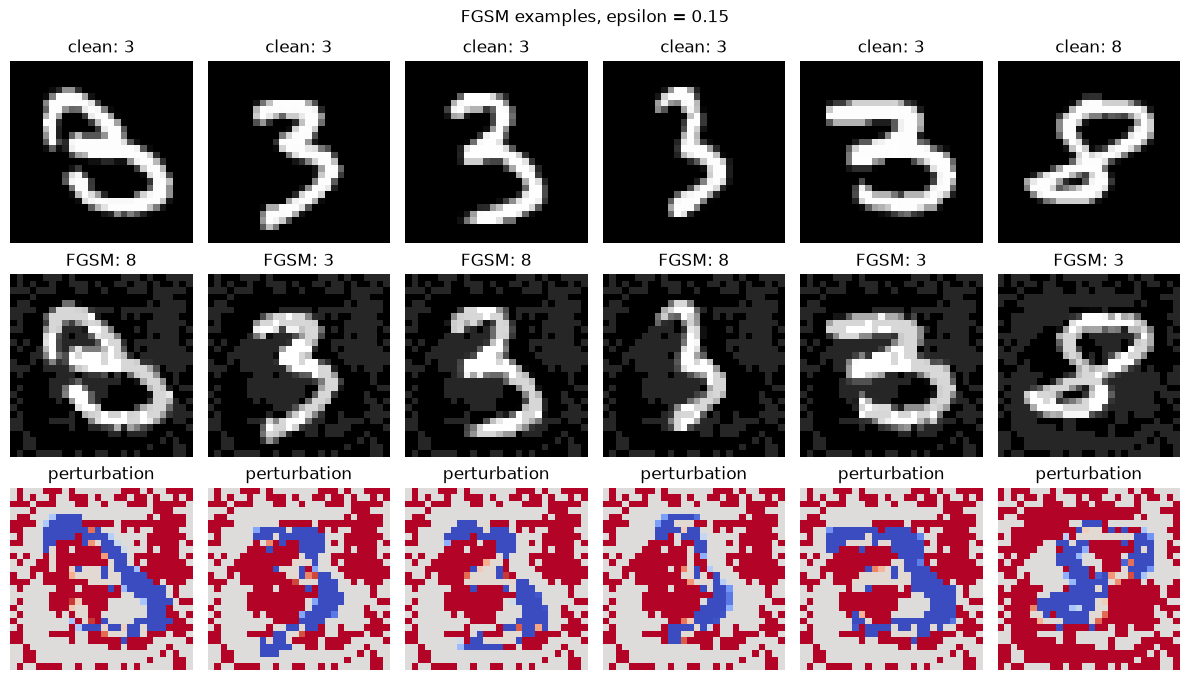

In [12]:
def show_binary_adversarials(model, loader, epsilon, n=6):

    model.eval()

    # get first batch and take first n images
    x, y = next(iter(loader))
    x = x[:n].to(device)
    y = y[:n].to(device)

    # create adversarial examples
    x_adv = fgsm_attack(model, x, y, epsilon, bce)

    # predictions before and after FGSM
    with torch.no_grad():
        pred_clean = (model(x) > 0.5).long().cpu()
        pred_adv = (model(x_adv) > 0.5).long().cpu()

    labels = {0: "3", 1: "8"}

    # move images back to CPU for plotting
    x = x.cpu()
    x_adv = x_adv.cpu()

    perturbation = x_adv - x

    fig, axes = plt.subplots(3, n, figsize=(2 * n, 7))

    for i in range(n):

        # clean image
        axes[0, i].imshow(x[i].view(28, 28), cmap="gray")
        axes[0, i].set_title("clean: " + labels[pred_clean[i].item()])
        axes[0, i].axis("off")

        # adversarial image
        axes[1, i].imshow(x_adv[i].view(28, 28), cmap="gray")
        axes[1, i].set_title("FGSM: " + labels[pred_adv[i].item()])
        axes[1, i].axis("off")

        # perturbation
        axes[2, i].imshow(perturbation[i].view(28, 28), cmap="coolwarm")
        axes[2, i].set_title("perturbation")
        axes[2, i].axis("off")

    plt.suptitle("FGSM examples, epsilon = " + str(epsilon))
    plt.tight_layout()
    plt.show()


show_binary_adversarials(
    model_none,
    test_loader_bin,
    epsilon=0.15
)

Each perturbation column shows what FGSM added to an image (red = pixel became brighter,
blue = darker). Notice the perturbations look basically the same across all
six images. The pattern also traces the
digit's shape, i.e. the pixels the model actually uses to tell 3s from 8s.

## 1.6 Adversarial training

Here, we use a method called FGSM adversarial training (Goodfellow et al., 2015).

**How it works:** For each batch, we train the model using both the original images and adversarial versions of those images.

1. FGSM is applied to the current model to create an adversarial version of the batch.
2. We calculate the cross-entropy loss on the clean images and on the adversarial images.
3. The two losses are combined using a weighted average (`adv_weight=0.5`)


In [13]:
print("Training FGSM adversarial model:")
model_adv = train(BinaryLogReg(), train_loader_bin, binary=True, epochs=15, lr=0.05, adv_epsilon=0.15, adv_weight=0.5)
clean_acc = evaluate_clean(model_adv, test_loader_bin, binary=True)

print("Clean test adversarial accuracy:", round(clean_acc, 4))

Training FGSM adversarial model:
epoch 1 | loss: 0.4524 | train acc: 0.9155
epoch 5 | loss: 0.369 | train acc: 0.9322
epoch 10 | loss: 0.3662 | train acc: 0.9337
epoch 15 | loss: 0.369 | train acc: 0.9331
Clean test adversarial accuracy: 0.9451


In [14]:
# add adversarial training results
adv_accs = []

for eps in EPSILONS_MNIST:
    if eps == 0:
        acc = evaluate_clean(model_adv, test_loader_bin, binary=True)
    else:
        acc = evaluate_fgsm(model_adv, test_loader_bin, eps, binary=True)

    adv_accs.append(acc)

results_bin["adversarial training"] = adv_accs

# show results
print("epsilon:", *EPSILONS_MNIST)

for name, accs in results_bin.items():
    print(name, ":",  *[round(a, 3) for a in accs])

epsilon: 0.0 0.02 0.05 0.1 0.15 0.2 0.25
no regularization : 0.968 0.935 0.779 0.387 0.118 0.018 0.001
l2 : 0.966 0.928 0.778 0.398 0.149 0.03 0.001
l1 : 0.968 0.941 0.83 0.483 0.197 0.043 0.005
gaussian noise : 0.968 0.968 0.967 0.966 0.966 0.966 0.962
random sign noise : 0.968 0.966 0.963 0.963 0.949 0.922 0.895
adversarial training : 0.945 0.934 0.916 0.866 0.786 0.66 0.48


Let's now check whether adversarial training also reduces $|w|_1$ in a similar way to L1 regularization. If it does, this could help explain why adversarial training improves the robustness of logistic regression models against adversarial attacks.


In [15]:
binary_models_all = binary_models + [("adversarial training", model_adv)]

rows = []

for name, model in binary_models_all:
    w = model.linear.weight.detach().cpu().flatten()

    l1_norm = w.abs().sum().item()
    l2_norm = w.norm().item()
    inf_norm = w.abs().max().item()
    n_zero = (w.abs() < 1e-6).sum().item()

    rows.append({
        "model": name,
        "L1 norm": round(l1_norm, 2),
        "L2 norm": round(l2_norm, 2),
        "Inf norm": round(inf_norm, 4),
        "zeros": n_zero
    })

pd.DataFrame(rows)

,model,L1 norm,L2 norm,Inf norm,zeros
0,no regularization,103.71,5.69,0.8181,0
1,l2,102.21,5.59,0.7911,0
2,l1,84.59,5.22,0.8092,42
3,adversarial training,16.63,3.06,1.2058,1


# Part 2 - Multiclass (softmax) logistic regression on MNIST

We now use all ten digits with the softmax

In [16]:
mc_none = train(MulticlassLogReg(), train_loader, binary=False, lr=0.05, reg_type=None)

print("")

mc_l2 = train(MulticlassLogReg(), train_loader, binary=False, lr=0.05, reg_type='l2', reg_strength=0.0001)

print("")

mc_l1 = train(MulticlassLogReg(), train_loader, binary=False, lr=0.05, reg_type='l1', reg_strength=0.0001)

print("")

mc_models = [("no regularization", mc_none), ("l2", mc_l2), ("l1", mc_l1)]
print("Test accuracy (none):", round(evaluate_clean(mc_none, test_loader, binary=False), 4))
print("Test accuracy (l2):", round(evaluate_clean(mc_l2, test_loader, binary=False), 4))
print("Test accuracy (l1):", round(evaluate_clean(mc_l1, test_loader, binary=False), 4))

epoch 1 | loss: 0.4074 | train acc: 0.8848
epoch 5 | loss: 0.2788 | train acc: 0.9219
epoch 10 | loss: 0.2652 | train acc: 0.9266
epoch 15 | loss: 0.259 | train acc: 0.928

epoch 1 | loss: 0.4106 | train acc: 0.8842
epoch 5 | loss: 0.2889 | train acc: 0.9212
epoch 10 | loss: 0.2792 | train acc: 0.9257
epoch 15 | loss: 0.2755 | train acc: 0.9267

epoch 1 | loss: 0.4504 | train acc: 0.8851
epoch 5 | loss: 0.3435 | train acc: 0.9185
epoch 10 | loss: 0.3377 | train acc: 0.9214
epoch 15 | loss: 0.3355 | train acc: 0.9219

Test accuracy (none): 0.9254
Test accuracy (l2): 0.9254
Test accuracy (l1): 0.9218


## 2.1 Looking at the weight vectors

With ten classes there are ten weight vectors. We display the weight matrix rows as images, and print out the $\ell^1$ and the $\ell^2$ norms of the weights as well as the features equal to zero.

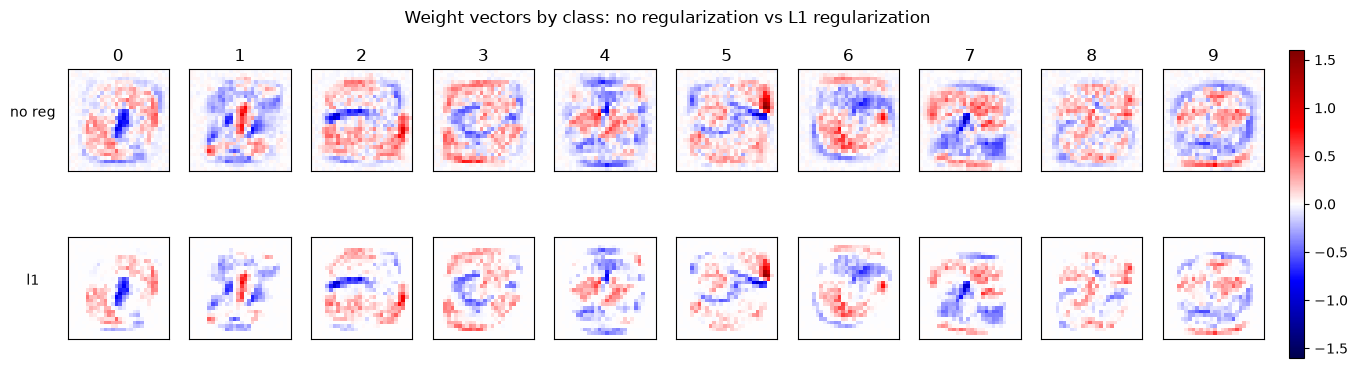

In [17]:
fig, axes = plt.subplots(2, 10, figsize=(16, 4))

# get all weights first so both rows use the same color scale
all_weights = []

for k in range(10):
    all_weights.append(mc_none.linear.weight[k].detach().cpu())
    all_weights.append(mc_l1.linear.weight[k].detach().cpu())

all_weights = torch.stack(all_weights)
vmax = all_weights.abs().max().item()

models_to_show = [("no reg", mc_none), ("l1", mc_l1)]

for row, (name, model) in enumerate(models_to_show):
    for k in range(10):
        w = model.linear.weight[k].detach().cpu().view(28, 28)

        im = axes[row, k].imshow(
            w,
            cmap="seismic",
            vmin=-vmax,
            vmax=vmax
        )

        axes[row, k].set_xticks([])
        axes[row, k].set_yticks([])

        if row == 0:
            axes[row, k].set_title(str(k))

    axes[row, 0].set_ylabel(name, rotation=0, labelpad=25)

fig.colorbar(im, ax=axes, fraction=0.015, pad=0.02)
plt.suptitle("Weight vectors by class: no regularization vs L1 regularization")
plt.show()

In [18]:
rows = []

for name, model in mc_models:
    W = model.linear.weight.detach().cpu().flatten()

    l1_norm = W.abs().sum().item()
    l2_norm = W.norm().item()
    inf_norm = W.abs().max().item()
    n_zero = (W.abs() < 1e-6).sum().item()

    rows.append({
        "model": name,
        "L1 norm": round(l1_norm, 2),
        "L2 norm": round(l2_norm, 2),
        "Inf norm": round(inf_norm, 4),
        "zeros": n_zero
    })

pd.DataFrame(rows)

,model,L1 norm,L2 norm,Inf norm,zeros
0,no regularization,1057.59,18.03,1.6016,0
1,l2,945.45,16.23,1.3943,0
2,l1,573.42,13.68,1.4856,338


## 2.2 FGSM on the multiclass models
Same idea as 1.3

In [19]:

results_mc = {}
for name, m in mc_models:
    accs = []
    for eps in EPSILONS_MNIST:
        if eps == 0.0:
            accs.append(evaluate_clean(m, test_loader, binary=False)) # clean accuracy
        else:
            a = evaluate_fgsm(m, test_loader, eps, binary=False)
            accs.append(a)
    results_mc[name] = accs
    print(name, *[round(a, 3) for a in accs])

no regularization 0.925 0.828 0.485 0.072 0.005 0.001 0.0
l2 0.925 0.839 0.533 0.092 0.006 0.0 0.0
l1 0.922 0.863 0.687 0.211 0.036 0.004 0.0


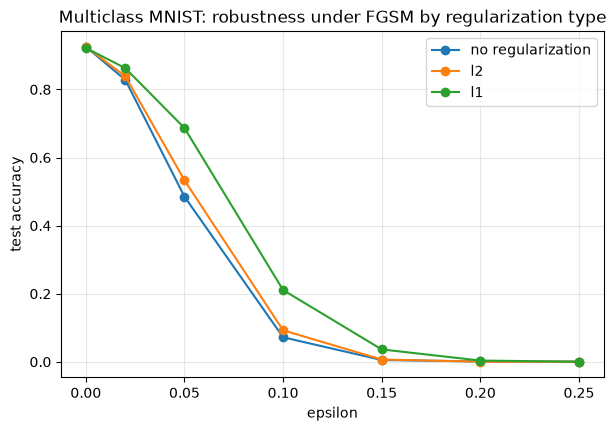

In [20]:
# plot accuracy vs attack strength
plt.figure(figsize=(7, 4.5))
for name, accs in results_mc.items():
    plt.plot(EPSILONS_MNIST, accs, marker="o", label=name)
plt.xlabel("epsilon")
plt.ylabel("test accuracy")
plt.title("Multiclass MNIST: robustness under FGSM by regularization type")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 2.3 Comparison with random noise

In [21]:
gaussian_accs = []

for eps in EPSILONS_MNIST:
    if eps == 0.0:
        acc = evaluate_clean(mc_none, test_loader, binary=False)
    else:
        acc = evaluate_noise(mc_none, test_loader, eps, gaussian_noise_attack, binary=False)
    gaussian_accs.append(acc)

results_mc["gaussian noise"] = gaussian_accs
print("gaussian noise:", *[round(a, 3) for a in gaussian_accs])

random_sign_accs = []

for eps in EPSILONS_MNIST:

    if eps == 0.0:
        acc = evaluate_clean(mc_none, test_loader, binary=False)

    else:
        acc = evaluate_noise(mc_none, test_loader, eps, random_sign_attack, binary=False)
    random_sign_accs.append(acc)

results_mc["random sign noise"] = random_sign_accs

print("random sign noise:", *[round(a, 3) for a in random_sign_accs])

gaussian noise: 0.925 0.925 0.925 0.923 0.921 0.917 0.914
random sign noise: 0.925 0.925 0.92 0.894 0.815 0.71 0.613


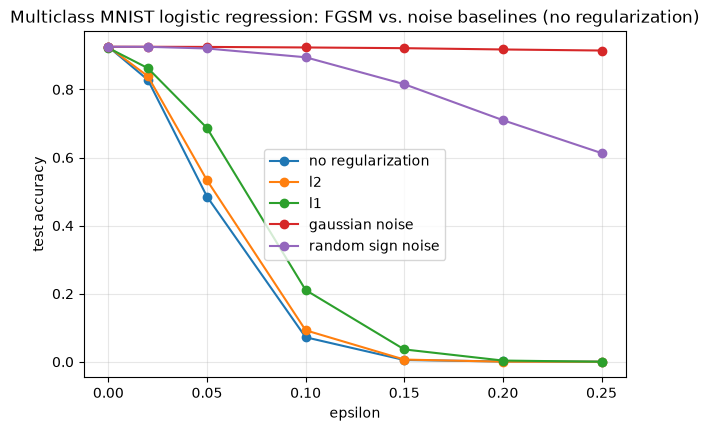

In [22]:
plt.figure(figsize=(7, 4.5))
for name, accs in results_mc.items():
    plt.plot(EPSILONS_MNIST, accs, marker="o", label=name)
plt.xlabel("epsilon")
plt.ylabel("test accuracy")
plt.title("Multiclass MNIST logistic regression: FGSM vs. noise baselines (no regularization)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Comparing the theoretical max change to the actual change
Since each class has its own row of $W$, the per-class theoretical max is averaged into a single number, so the output matches the binary version's shape.

In [23]:
def compare_output_change_multiclass(model, x, y, epsilon, noise_fns):

    # average theoretical maximum change across classes
    W = model.linear.weight.detach()
    theoretical_max = epsilon * W.abs().sum().item() / W.size(0)

    x = x.to(device)
    y = y.to(device)

    # clean logits
    x_flat = x.view(x.size(0), -1)
    clean_output = model.linear(x_flat)

    # FGSM
    x_fgsm = fgsm_attack(model, x, y, epsilon, F.cross_entropy)

    x_fgsm_flat = x_fgsm.view(x_fgsm.size(0), -1)
    fgsm_output = model.linear(x_fgsm_flat)

    fgsm_change = (fgsm_output - clean_output).abs().mean().item()
    fgsm_percent = (fgsm_change / theoretical_max) * 100

    rows = []

    rows.append({
        "type": "theoretical max",
        "mean change": round(theoretical_max, 4),
        "% of max": 100
    })

    rows.append({
        "type": "FGSM",
        "mean change": round(fgsm_change, 4),
        "% of max": round(fgsm_percent, 1)
    })

    # noise attacks
    for name, noise_fn in noise_fns.items():

        x_noise = noise_fn(x, epsilon)

        x_noise_flat = x_noise.view(x_noise.size(0), -1)
        noise_output = model.linear(x_noise_flat)

        noise_change = (noise_output - clean_output).abs().mean().item()
        noise_percent = (noise_change / theoretical_max) * 100

        rows.append({
            "type": name,
            "mean change": round(noise_change, 4),
            "% of max": round(noise_percent, 1)
        })

    return pd.DataFrame(rows)
x_batch, y_batch = next(iter(test_loader))

compare_output_change_multiclass(
    mc_none,
    x_batch,
    y_batch,
    epsilon=0.15,
    noise_fns={
        "gaussian noise": gaussian_noise_attack,
        "random sign noise": random_sign_attack
    }
)

,type,mean change,% of max
0,theoretical max,15.8638,100.0
1,FGSM,2.9895,18.8
2,gaussian noise,0.3800,2.4
3,random sign noise,1.4122,8.9


## 2.4 Visualizing adversarial examples

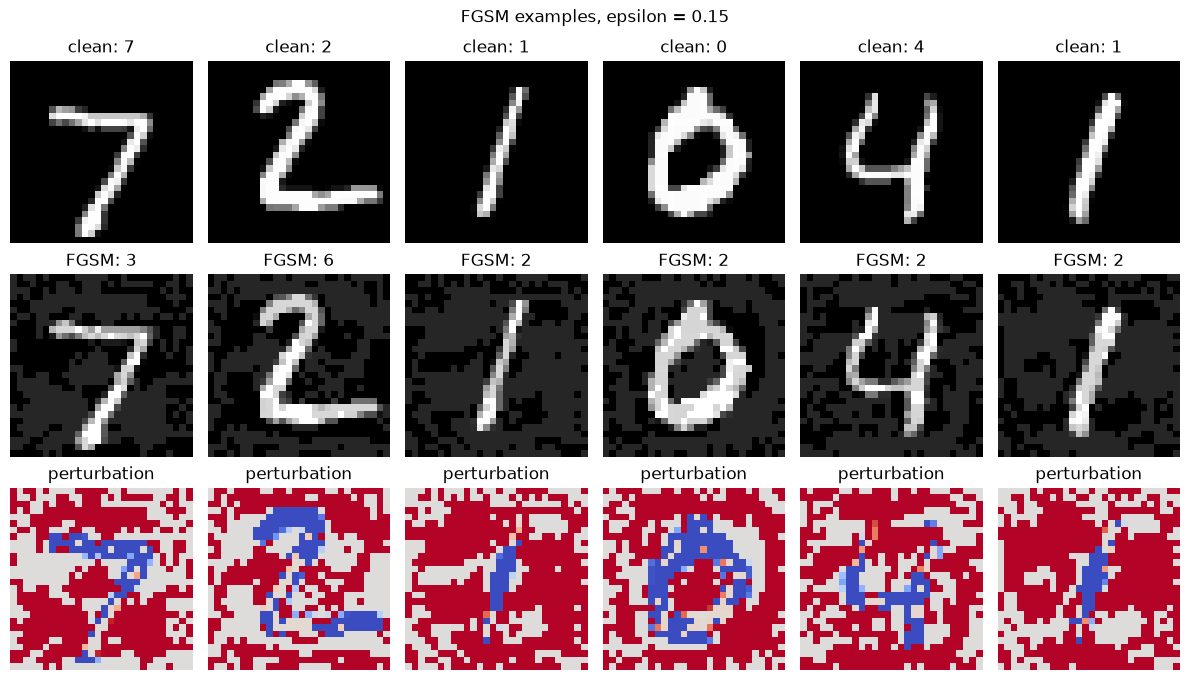

In [24]:
def show_multiclass_adversarials(model, loader, epsilon, n=6):

    model.eval()

    # get first batch and take first n images
    x, y = next(iter(loader))
    x = x[:n].to(device)
    y = y[:n].to(device)

    # create adversarial examples
    x_adv = fgsm_attack(model, x, y, epsilon, F.cross_entropy)

    # predictions before and after FGSM
    with torch.no_grad():
        pred_clean = model(x).argmax(1).cpu()
        pred_adv = model(x_adv).argmax(1).cpu()

    # move images back to CPU for plotting
    x = x.cpu()
    x_adv = x_adv.cpu()

    perturbation = x_adv - x

    fig, axes = plt.subplots(3, n, figsize=(2 * n, 7))

    for i in range(n):

        # clean image
        axes[0, i].imshow(x[i].view(28, 28), cmap="gray")
        axes[0, i].set_title("clean: " + str(pred_clean[i].item()))
        axes[0, i].axis("off")

        # adversarial image
        axes[1, i].imshow(x_adv[i].view(28, 28), cmap="gray")
        axes[1, i].set_title("FGSM: " + str(pred_adv[i].item()))
        axes[1, i].axis("off")

        # perturbation
        axes[2, i].imshow(
            perturbation[i].view(28, 28),
            cmap="coolwarm"
        )
        axes[2, i].set_title("perturbation")
        axes[2, i].axis("off")

    plt.suptitle("FGSM examples, epsilon = " + str(epsilon))
    plt.tight_layout()
    plt.show()


show_multiclass_adversarials(
    mc_none,
    test_loader,
    epsilon=0.15
)

## 2.5 Adversarial training

In [25]:
print("Training FGSM adversarial model:")
mc_adv = train(MulticlassLogReg(), train_loader, binary=False, epochs=15, lr=0.05, adv_epsilon=0.15, adv_weight=0.5)
clean_acc = evaluate_clean(mc_adv, test_loader, binary=False)
print("Clean test adversarial accuracy:", round(clean_acc, 4))

Training FGSM adversarial model:
epoch 1 | loss: 1.0578 | train acc: 0.849
epoch 5 | loss: 0.9947 | train acc: 0.861
epoch 10 | loss: 0.9978 | train acc: 0.8597
epoch 15 | loss: 0.9972 | train acc: 0.86
Clean test adversarial accuracy: 0.8712


In [26]:
# add adversarial training results
adv_accs = []

for eps in EPSILONS_MNIST:
    if eps == 0.0:
        #acc = evaluate_clean(mc_adv, test_loader_bin, binary=False)
        acc = clean_acc
    else:
        acc = evaluate_fgsm(mc_adv, test_loader, eps, binary=False)

    adv_accs.append(acc)

results_mc["adversarial training"] = adv_accs

# show results
print("epsilon:", *EPSILONS_MNIST)

for name, accs in results_mc.items():
    print(name, *[round(a, 3) for a in accs])

epsilon: 0.0 0.02 0.05 0.1 0.15 0.2 0.25
no regularization 0.925 0.828 0.485 0.072 0.005 0.001 0.0
l2 0.925 0.839 0.533 0.092 0.006 0.0 0.0
l1 0.922 0.863 0.687 0.211 0.036 0.004 0.0
gaussian noise 0.925 0.925 0.925 0.923 0.921 0.917 0.914
random sign noise 0.925 0.925 0.92 0.894 0.815 0.71 0.613
adversarial training 0.871 0.844 0.796 0.675 0.507 0.31 0.115


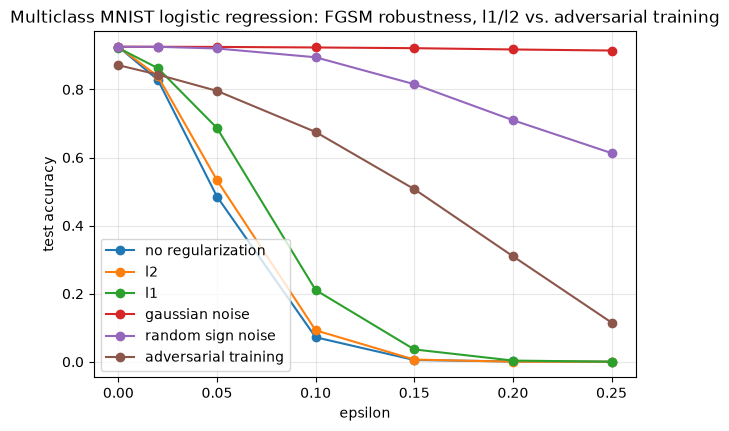

In [27]:
# re-plot with all four models together
plt.figure(figsize=(7, 4.5))
for name, accs in results_mc.items():
    plt.plot(EPSILONS_MNIST, accs, marker="o", label=name)
plt.xlabel("epsilon")
plt.ylabel("test accuracy")
plt.title("Multiclass MNIST logistic regression: FGSM robustness, l1/l2 vs. adversarial training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [28]:
# does adversarial training also shrink W_1, the way L1 does?
mc_models_all = mc_models + [("adversarial training", mc_adv)]

rows = []

for name, model in mc_models_all:
    W = model.linear.weight.detach().cpu().flatten()

    l1_norm = W.abs().sum().item()
    l2_norm = W.norm().item()
    inf_norm = W.abs().max().item()
    n_zero = (W.abs() < 1e-6).sum().item()

    rows.append({
        "model": name,
        "L1 norm": round(l1_norm, 2),
        "L2 norm": round(l2_norm, 2),
        "Inf norm": round(inf_norm, 4),
        "zeros": n_zero
    })

pd.DataFrame(rows)

,model,L1 norm,L2 norm,Inf norm,zeros
0,no regularization,1057.59,18.03,1.6016,0
1,l2,945.45,16.23,1.3943,0
2,l1,573.42,13.68,1.4856,338
3,adversarial training,241.30,6.62,1.0122,1


# Part 3 - Binary logistic regression on STL-10

So far we studied logistic regression on MNIST, where each input is a $784$-dimensional vector. We now repeat the analysis on STL-10, where each image is $3 \times 96 \times 96 = 27648$-dimensional.   

**A warning up front about accuracy.** A linear model on raw STL-10 pixels is a poor
*classifier* but we still consider it for our adversarial comparisons.

We start by loading the STL-10 dataset and preparing the training and test sets.


In [32]:
from advrobust.data import load_stl10

stl = load_stl10()

STL_DIM = stl["STL_DIM"]

stl_train = stl["stl_train"]
stl_test = stl["stl_test"]

stl_train_bin = stl["stl_train_bin"]
stl_test_bin = stl["stl_test_bin"]

stl_train_loader_bin = stl["stl_train_loader_bin"]
stl_test_loader_bin = stl["stl_test_loader_bin"]

stl_train_loader = stl["stl_train_loader"]
stl_test_loader = stl["stl_test_loader"]

stl_name_a = stl["stl_name_a"]
stl_name_b = stl["stl_name_b"]
# the functions defined for training on the MNIST dataset can be reused for STL-10 as well

## 3.1 Binary logistic regression on STL-10

We train a binary logistic regression model, where we choose images of cats and dogs for the two classes to be identified. We chose cats and dogs because these classes could easily be confused by the models

We can reuse the models and the evaluation function since it never assumes input shape anywhere.

In [33]:
# lr=0.05 diverges here
# 0.0005 seems stable
print("Training unregularized model:")
stl_model_none = train(BinaryLogReg(in_features=STL_DIM), stl_train_loader_bin, binary=True, epochs=60, lr=0.0005, reg_type=None)

print("")

print("Training l2-regularized model:")
stl_model_l2 = train(BinaryLogReg(in_features=STL_DIM), stl_train_loader_bin, binary=True, epochs=60, lr=0.0005, reg_type='l2', reg_strength=0.0001)

print("")

print("Training l1-regularized model:")
stl_model_l1 = train(BinaryLogReg(in_features=STL_DIM), stl_train_loader_bin, binary=True, epochs=60, lr=0.0005, reg_type='l1', reg_strength=0.0001)

print("")

print("Test accuracy (none):", round(evaluate_clean(stl_model_none, stl_test_loader_bin, binary=True), 4))
print("Test accuracy (l2):", round(evaluate_clean(stl_model_l2, stl_test_loader_bin, binary=True), 4))
print("Test accuracy (l1):", round(evaluate_clean(stl_model_l1, stl_test_loader_bin, binary=True), 4))

Training unregularized model:
epoch 1 | loss: 0.7018 | train acc: 0.493
epoch 5 | loss: 0.6571 | train acc: 0.61
epoch 10 | loss: 0.6531 | train acc: 0.6
epoch 15 | loss: 0.6034 | train acc: 0.692
epoch 20 | loss: 0.5904 | train acc: 0.695
epoch 25 | loss: 0.6003 | train acc: 0.671
epoch 30 | loss: 0.5576 | train acc: 0.745
epoch 35 | loss: 0.5488 | train acc: 0.734
epoch 40 | loss: 0.5303 | train acc: 0.779
epoch 45 | loss: 0.5189 | train acc: 0.782
epoch 50 | loss: 0.5084 | train acc: 0.782
epoch 55 | loss: 0.5043 | train acc: 0.798
epoch 60 | loss: 0.4946 | train acc: 0.783

Training l2-regularized model:
epoch 1 | loss: 0.7058 | train acc: 0.501
epoch 5 | loss: 0.677 | train acc: 0.568
epoch 10 | loss: 0.643 | train acc: 0.622
epoch 15 | loss: 0.5983 | train acc: 0.704
epoch 20 | loss: 0.5871 | train acc: 0.716
epoch 25 | loss: 0.576 | train acc: 0.719
epoch 30 | loss: 0.5568 | train acc: 0.741
epoch 35 | loss: 0.5467 | train acc: 0.762
epoch 40 | loss: 0.5299 | train acc: 0.785
ep

## 3.2 Looking at the weights

The weight vector is now $(3, 96, 96)$, not $(28, 28)$. We normalize each channel's signed weights into a
color image directly

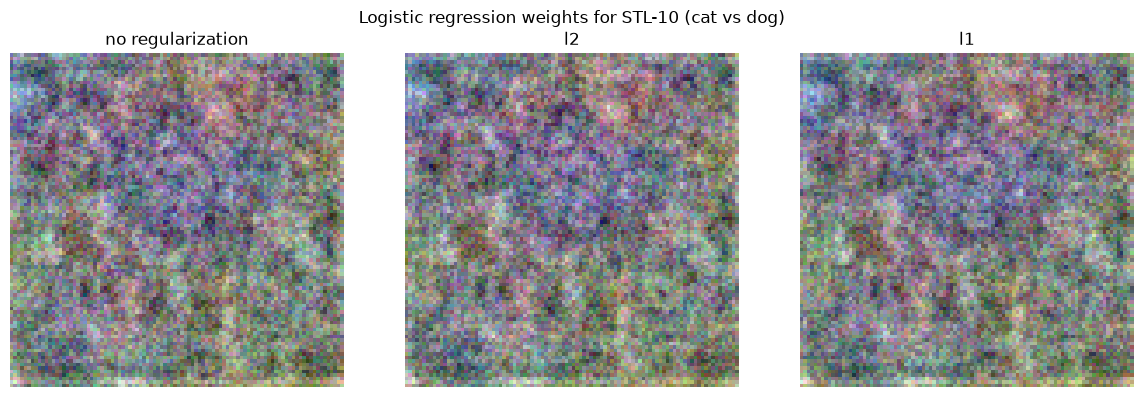

In [34]:
stl_models = [("no regularization", stl_model_none), ("l2", stl_model_l2), ("l1", stl_model_l1)]



# use the same scale for all models
all_weights = []

for name, model in stl_models:
    w = model.linear.weight.detach().cpu().view(3, 96, 96)
    all_weights.append(w)

vmax = max(w.abs().max().item() for w in all_weights)


fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (name, model) in zip(axes, stl_models):

    # reshape weights back to RGB image shape
    w = model.linear.weight.detach().cpu().view(3, 96, 96)

    # scale weights to [0, 1] so they can be shown as an RGB image
    w_img = ((w / vmax) + 1) / 2
    w_img = w_img.permute(1, 2, 0).clamp(0, 1)

    ax.imshow(w_img)
    ax.set_title(name)
    ax.axis("off")

plt.suptitle("Logistic regression weights for STL-10 (cat vs dog)")
plt.tight_layout()
plt.show()

In [35]:
rows = []

for name, model in stl_models:
    W = model.linear.weight.detach().cpu().flatten()

    l1_norm = W.abs().sum().item()
    l2_norm = W.norm().item()
    inf_norm = W.abs().max().item()
    n_zero = (W.abs() < 1e-6).sum().item()

    rows.append({
        "model": name,
        "L1 norm": round(l1_norm, 2),
        "L2 norm": round(l2_norm, 2),
        "Inf norm": round(inf_norm, 4),
        "zeros": n_zero
    })

pd.DataFrame(rows)

,model,L1 norm,L2 norm,Inf norm,zeros
0,no regularization,116.73,0.87,0.0207,5
1,l2,116.39,0.87,0.0198,3
2,l1,111.55,0.84,0.0203,2


## 3.3 FGSM on the models

Reusing `evaluate_fgsm_binary` directly, it never assumed input shape anywhere.  


**Note on epsilon scale:** MNIST's epsilons degrade the model basically at the lowest epsilon. We use a smaller range below instead of reusing previously used epsilons.

In [36]:
# now decrease the scale of epsilons
EPSILONS_STL = [0, 0.002, 0.005, 0.01, 0.015, 0.02, 0.025]

# Accuracy for different epsilons
results_stl_bin = {}
for name, m in stl_models:
  accs = []
  for eps in EPSILONS_STL:
        if eps == 0.0:
            acc = evaluate_clean(m, stl_test_loader_bin, binary=True) # clean accuracy
        else:
            acc = evaluate_fgsm(m, stl_test_loader_bin, eps, binary=True)
        accs.append(acc)
  results_stl_bin[name] = accs
  print(name, ":", *[round(a, 3) for a in accs])

no regularization : 0.59 0.455 0.296 0.119 0.037 0.008 0.004
l2 : 0.585 0.463 0.304 0.123 0.033 0.009 0.003
l1 : 0.583 0.456 0.297 0.129 0.044 0.011 0.004


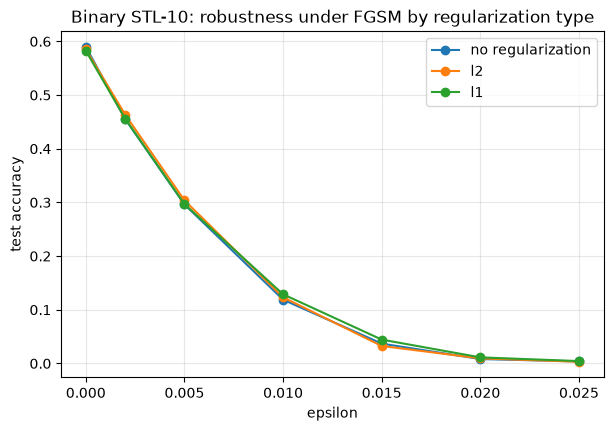

In [37]:
plt.figure(figsize=(7, 4.5))
for name, accs in results_stl_bin.items():
    plt.plot(EPSILONS_STL, accs, marker="o", label=name)
plt.xlabel("epsilon")
plt.ylabel("test accuracy")
plt.title(f"Binary STL-10: robustness under FGSM by regularization type")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 3.4 Comparison with random noise

In [38]:
gaussian_accs = []

for eps in EPSILONS_STL:
    if eps == 0:
        acc = evaluate_clean(stl_model_none, stl_test_loader_bin, binary=True)
    else:
        acc = evaluate_noise(stl_model_none, stl_test_loader_bin, eps, gaussian_noise_attack, binary=True)
    gaussian_accs.append(acc)

results_stl_bin["gaussian noise"] = gaussian_accs
print("gaussian noise:", *[round(a, 3) for a in gaussian_accs])


random_sign_accs = []

for eps in EPSILONS_STL:
    if eps == 0.0:
        acc = evaluate_clean(stl_model_none, stl_test_loader_bin, binary=True)
    else:
        acc = evaluate_noise(stl_model_none, stl_test_loader_bin, eps, random_sign_attack, binary=True)
    random_sign_accs.append(acc)

results_stl_bin["random sign noise"] = random_sign_accs
print("random sign noise:", *[round(a, 3) for a in random_sign_accs])

gaussian noise: 0.59 0.59 0.589 0.589 0.589 0.588 0.59
random sign noise: 0.59 0.59 0.588 0.591 0.589 0.589 0.594


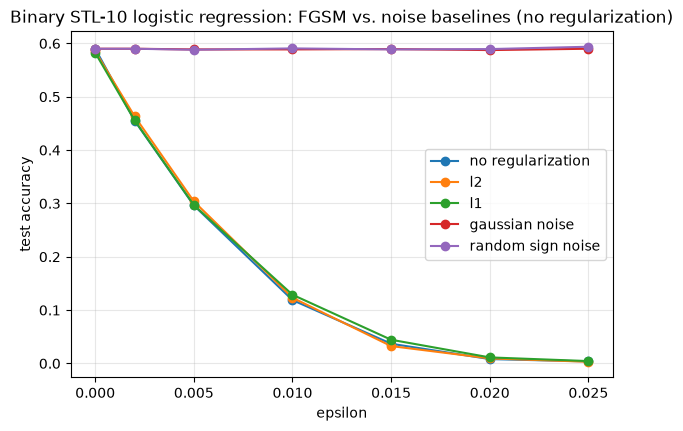

In [39]:
plt.figure(figsize=(7, 4.5))
for name, accs in results_stl_bin.items():
    plt.plot(EPSILONS_STL, accs, marker="o", label=name)
plt.xlabel("epsilon")
plt.ylabel("test accuracy")
plt.title("Binary STL-10 logistic regression: FGSM vs. noise baselines (no regularization)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Comparing the theoretical max change to the actual change

In [40]:
x_batch, y_batch = next(iter(stl_test_loader_bin))

compare_output_change(
    stl_model_none,
    x_batch,
    y_batch,
    epsilon=0.015,
    noise_fns={
        "gaussian noise": gaussian_noise_attack,
        "random sign noise": random_sign_attack
    }
)

,type,mean change,% of max
0,theoretical max,1.7509,100.0
1,FGSM,1.7374,99.2
2,gaussian noise,0.0036,0.2
3,random sign noise,0.0112,0.6


## 3.5 Visualizing adversarial examples

`fgsm_attack` itself is unchanged, but the display function needs a new version for RGB images. Also, since the accuracy of these models is low, we want to make sure each image chosen is actually classified correctly. Otherwise, most of them might me misclassified in the first place, and it's not an interesting representation.

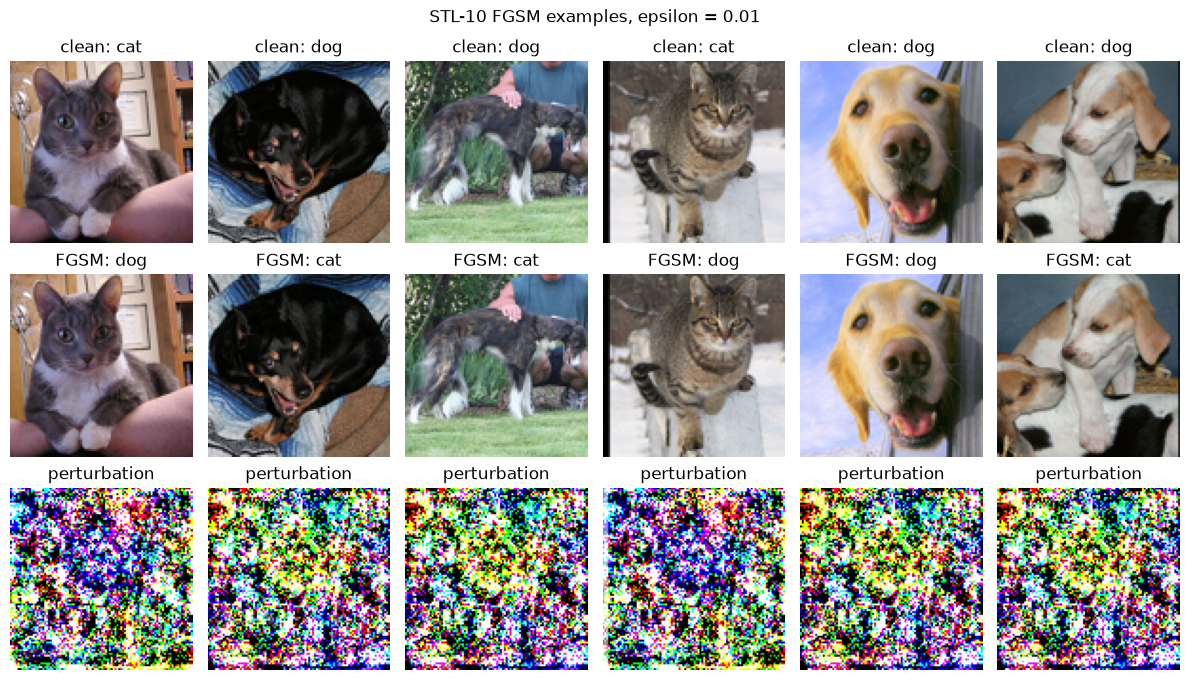

In [41]:
def show_stl_binary_adversarials(model, loader, epsilon, n=6):

    model.eval()

    # find correctly classified examples
    x_list = []
    y_list = []

    for x_batch, y_batch in loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        with torch.no_grad():
            pred = (model(x_batch) > 0.5).long()

        correct = pred == y_batch

        x_list.append(x_batch[correct])
        y_list.append(y_batch[correct])

        if sum(len(x) for x in x_list) >= n:
            break

    x = torch.cat(x_list)[:n]
    y = torch.cat(y_list)[:n]

    # create adversarial examples
    x_adv = fgsm_attack(model, x, y, epsilon, bce)

    with torch.no_grad():
        pred_clean = (model(x) > 0.5).long().cpu()
        pred_adv = (model(x_adv) > 0.5).long().cpu()

    labels = {
        0: stl_name_a,
        1: stl_name_b
    }

    x = x.cpu()
    x_adv = x_adv.cpu()

    perturbation = x_adv - x

    fig, axes = plt.subplots(3, n, figsize=(2 * n, 7))

    for i in range(n):

        # reshape back to RGB image
        clean_img = x[i].view(3, 96, 96).permute(1, 2, 0)
        adv_img = x_adv[i].view(3, 96, 96).permute(1, 2, 0)

        # scale perturbation so it can be shown as RGB
        pert = perturbation[i].view(3, 96, 96)
        pert_img = ((pert / epsilon) + 1) / 2
        pert_img = pert_img.permute(1, 2, 0).clamp(0, 1)

        axes[0, i].imshow(clean_img)
        axes[0, i].set_title("clean: " + labels[pred_clean[i].item()])
        axes[0, i].axis("off")

        axes[1, i].imshow(adv_img)
        axes[1, i].set_title("FGSM: " + labels[pred_adv[i].item()])
        axes[1, i].axis("off")

        axes[2, i].imshow(pert_img)
        axes[2, i].set_title("perturbation")
        axes[2, i].axis("off")

    plt.suptitle("STL-10 FGSM examples, epsilon = " + str(epsilon))
    plt.tight_layout()
    plt.show()


show_stl_binary_adversarials(
    stl_model_none,
    stl_test_loader_bin,
    epsilon=0.01
)

## 3.6 Adversarial training

In [42]:
print("Training FGSM adversarial model:")
stl_model_adv = train(BinaryLogReg(in_features=STL_DIM), stl_train_loader_bin, binary=True, epochs=60, lr=0.0005, adv_epsilon=0.015, adv_weight=0.5)
clean_acc = evaluate_clean(stl_model_adv, stl_test_loader_bin, binary=True)

print("Clean test adversarial accuracy:", round(clean_acc, 4))

Training FGSM adversarial model:
epoch 1 | loss: 1.0985 | train acc: 0.499
epoch 5 | loss: 0.9503 | train acc: 0.589
epoch 10 | loss: 0.8158 | train acc: 0.644
epoch 15 | loss: 0.7468 | train acc: 0.665
epoch 20 | loss: 0.7231 | train acc: 0.643
epoch 25 | loss: 0.7005 | train acc: 0.666
epoch 30 | loss: 0.6873 | train acc: 0.69
epoch 35 | loss: 0.7063 | train acc: 0.637
epoch 40 | loss: 0.6809 | train acc: 0.663
epoch 45 | loss: 0.6798 | train acc: 0.677
epoch 50 | loss: 0.704 | train acc: 0.601
epoch 55 | loss: 0.6801 | train acc: 0.662
epoch 60 | loss: 0.685 | train acc: 0.653
Clean test adversarial accuracy: 0.5819


In [43]:
# add adversarial training results
adv_accs = []

for eps in EPSILONS_STL:
    if eps == 0:
        acc = clean_acc
    else:
        acc = evaluate_fgsm(stl_model_adv, stl_test_loader_bin, eps, binary=True)

    adv_accs.append(acc)

results_stl_bin["adversarial training"] = adv_accs

# show results
print("epsilon:", *EPSILONS_STL)

for name, accs in results_stl_bin.items():
    print(name, *[round(a, 3) for a in accs])

epsilon: 0 0.002 0.005 0.01 0.015 0.02 0.025
no regularization 0.59 0.455 0.296 0.119 0.037 0.008 0.004
l2 0.585 0.463 0.304 0.123 0.033 0.009 0.003
l1 0.583 0.456 0.297 0.129 0.044 0.011 0.004
gaussian noise 0.59 0.59 0.589 0.589 0.589 0.588 0.59
random sign noise 0.59 0.59 0.588 0.591 0.589 0.589 0.594
adversarial training 0.582 0.552 0.506 0.429 0.351 0.292 0.236


In [44]:
stl_models_all = stl_models + [("adversarial training", stl_model_adv)]

rows = []

for name, model in stl_models_all:
    w = model.linear.weight.detach().cpu().flatten()

    l1_norm = w.abs().sum().item()
    l2_norm = w.norm().item()
    inf_norm = w.abs().max().item()
    n_zero = (w.abs() < 1e-6).sum().item()

    rows.append({
        "model": name,
        "L1 norm": round(l1_norm, 2),
        "L2 norm": round(l2_norm, 2),
        "Inf norm": round(inf_norm, 4),
        "zeros": n_zero
    })

pd.DataFrame(rows)

,model,L1 norm,L2 norm,Inf norm,zeros
0,no regularization,116.73,0.87,0.0207,5
1,l2,116.39,0.87,0.0198,3
2,l1,111.55,0.84,0.0203,2
3,adversarial training,15.98,0.27,0.0192,480


# Part 4 - Multiclass logistic regression on STL-10

In [45]:
stl_mc_none = train(MulticlassLogReg(in_features=STL_DIM), stl_train_loader, binary=False, epochs=60, lr=0.0005, reg_type=None)

print("")

stl_mc_l2 = train(MulticlassLogReg(in_features=STL_DIM), stl_train_loader, binary=False, epochs=60, lr=0.0005, reg_type='l2', reg_strength=0.0001)

print("")

stl_mc_l1 = train(MulticlassLogReg(in_features=STL_DIM), stl_train_loader, binary=False, epochs=60, lr=0.0005, reg_type='l1', reg_strength=0.0001)

print("")

stl_mc_models = [("no regularization", stl_mc_none), ("l2", stl_mc_l2), ("l1", stl_mc_l1)]
print("Test accuracy (none):", round(evaluate_clean(stl_mc_none, stl_test_loader, binary=False), 4))
print("Test accuracy (l2):", round(evaluate_clean(stl_mc_l2, stl_test_loader, binary=False), 4))
print("Test accuracy (l1):", round(evaluate_clean(stl_mc_l1, stl_test_loader, binary=False), 4))

epoch 1 | loss: 2.1067 | train acc: 0.2124
epoch 5 | loss: 1.8087 | train acc: 0.3498
epoch 10 | loss: 1.7409 | train acc: 0.3876
epoch 15 | loss: 1.6086 | train acc: 0.4382
epoch 20 | loss: 1.5404 | train acc: 0.4676
epoch 25 | loss: 1.5016 | train acc: 0.4908
epoch 30 | loss: 1.4431 | train acc: 0.514
epoch 35 | loss: 1.3925 | train acc: 0.5388
epoch 40 | loss: 1.355 | train acc: 0.5574
epoch 45 | loss: 1.3273 | train acc: 0.5674
epoch 50 | loss: 1.29 | train acc: 0.5898
epoch 55 | loss: 1.2539 | train acc: 0.6074
epoch 60 | loss: 1.2477 | train acc: 0.5976

epoch 1 | loss: 2.1095 | train acc: 0.2136
epoch 5 | loss: 1.7916 | train acc: 0.3648
epoch 10 | loss: 1.6926 | train acc: 0.3962
epoch 15 | loss: 1.618 | train acc: 0.4318
epoch 20 | loss: 1.5377 | train acc: 0.4724
epoch 25 | loss: 1.4754 | train acc: 0.5038
epoch 30 | loss: 1.4948 | train acc: 0.478
epoch 35 | loss: 1.407 | train acc: 0.5304
epoch 40 | loss: 1.3679 | train acc: 0.546
epoch 45 | loss: 1.341 | train acc: 0.5586


## 4.1 Looking at the weight norms

In [46]:
rows = []

for name, model in stl_mc_models:
    W = model.linear.weight.detach().cpu().flatten()

    l1_norm = W.abs().sum().item()
    l2_norm = W.norm().item()
    inf_norm = W.abs().max().item()
    n_zero = (W.abs() < 1e-6).sum().item()

    rows.append({
        "model": name,
        "L1 norm": round(l1_norm, 2),
        "L2 norm": round(l2_norm, 2),
        "Inf norm": round(inf_norm, 4),
        "zeros": n_zero
    })

pd.DataFrame(rows)

,model,L1 norm,L2 norm,Inf norm,zeros
0,no regularization,1357.65,3.23,0.0329,46
1,l2,1355.83,3.23,0.0350,48
2,l1,1135.51,2.86,0.0329,143


## 4.2 FGSM on the models

In [47]:
results_stl_mc = {}
for name, m in stl_mc_models:
    accs = []
    for eps in EPSILONS_STL:
        if eps == 0.0:
            accs.append(evaluate_clean(m, stl_test_loader, binary=False)) # clean accuracy
        else:
            a = evaluate_fgsm(m, stl_test_loader, eps, binary=False)
            accs.append(a)
    results_stl_mc[name] = accs
    print(name, *[round(a, 3) for a in accs])

no regularization 0.338 0.266 0.174 0.078 0.032 0.013 0.004
l2 0.34 0.258 0.159 0.075 0.03 0.011 0.005
l1 0.355 0.28 0.188 0.094 0.044 0.018 0.007


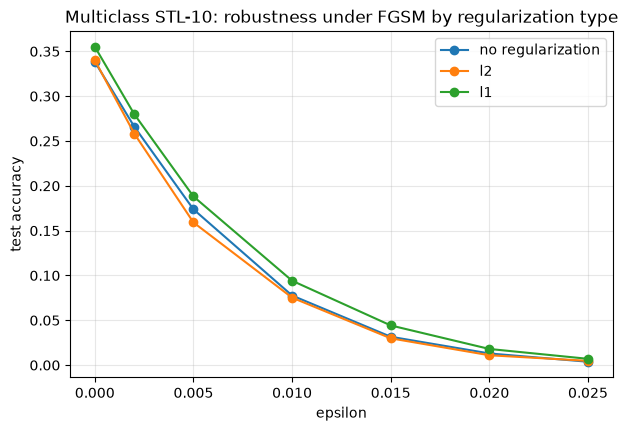

In [48]:
# plot accuracy vs attack strength
plt.figure(figsize=(7, 4.5))
for name, accs in results_stl_mc.items():
    plt.plot(EPSILONS_STL, accs, marker="o", label=name)
plt.xlabel("epsilon")
plt.ylabel("test accuracy")
plt.title("Multiclass STL-10: robustness under FGSM by regularization type")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 4.3 Comparison with random noise

In [49]:
gaussian_accs = []

for eps in EPSILONS_STL:
    if eps == 0.0:
        acc = evaluate_clean(stl_mc_none, stl_test_loader, binary=False)
    else:
        acc = evaluate_noise(stl_mc_none, stl_test_loader, eps, gaussian_noise_attack, binary=False)
    gaussian_accs.append(acc)

results_stl_mc["gaussian noise"] = gaussian_accs
print("gaussian noise:", *[round(a, 3) for a in gaussian_accs])

random_sign_accs = []

for eps in EPSILONS_STL:

    if eps == 0.0:
        acc = evaluate_clean(stl_mc_none, stl_test_loader, binary=False)

    else:
        acc = evaluate_noise(stl_mc_none, stl_test_loader, eps, random_sign_attack, binary=False)
    random_sign_accs.append(acc)

results_stl_mc["random sign noise"] = random_sign_accs

print("random sign noise:", *[round(a, 3) for a in random_sign_accs])

gaussian noise: 0.338 0.339 0.338 0.339 0.338 0.338 0.338
random sign noise: 0.338 0.339 0.338 0.338 0.337 0.338 0.338


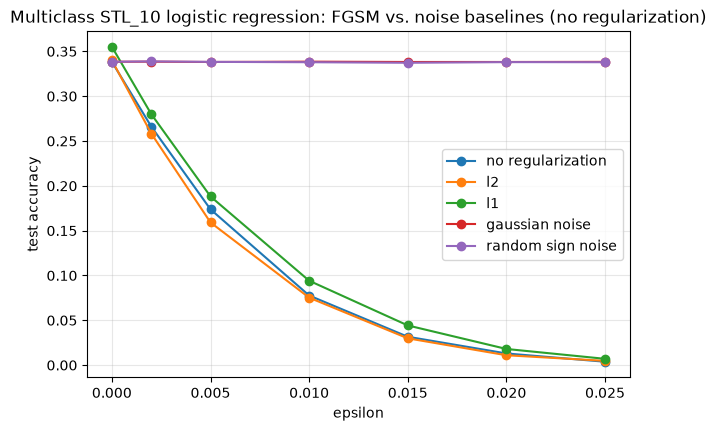

In [50]:
plt.figure(figsize=(7, 4.5))
for name, accs in results_stl_mc.items():
    plt.plot(EPSILONS_STL, accs, marker="o", label=name)
plt.xlabel("epsilon")
plt.ylabel("test accuracy")
plt.title("Multiclass STL_10 logistic regression: FGSM vs. noise baselines (no regularization)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Comparing the theoretical max change to the actual change

In [51]:
x_stl_mc_batch, y_stl_mc_batch = next(iter(stl_test_loader))

compare_output_change_multiclass(
    stl_mc_none,
    x_stl_mc_batch,
    y_stl_mc_batch,
    epsilon=0.015,
    noise_fns={
        "gaussian noise": gaussian_noise_attack,
        "random sign noise": random_sign_attack
    }
)

,type,mean change,% of max
0,theoretical max,2.0365,100.0
1,FGSM,0.3676,18.1
2,gaussian noise,0.0044,0.2
3,random sign noise,0.0147,0.7


## 4.4 Visualizing adversarial examples

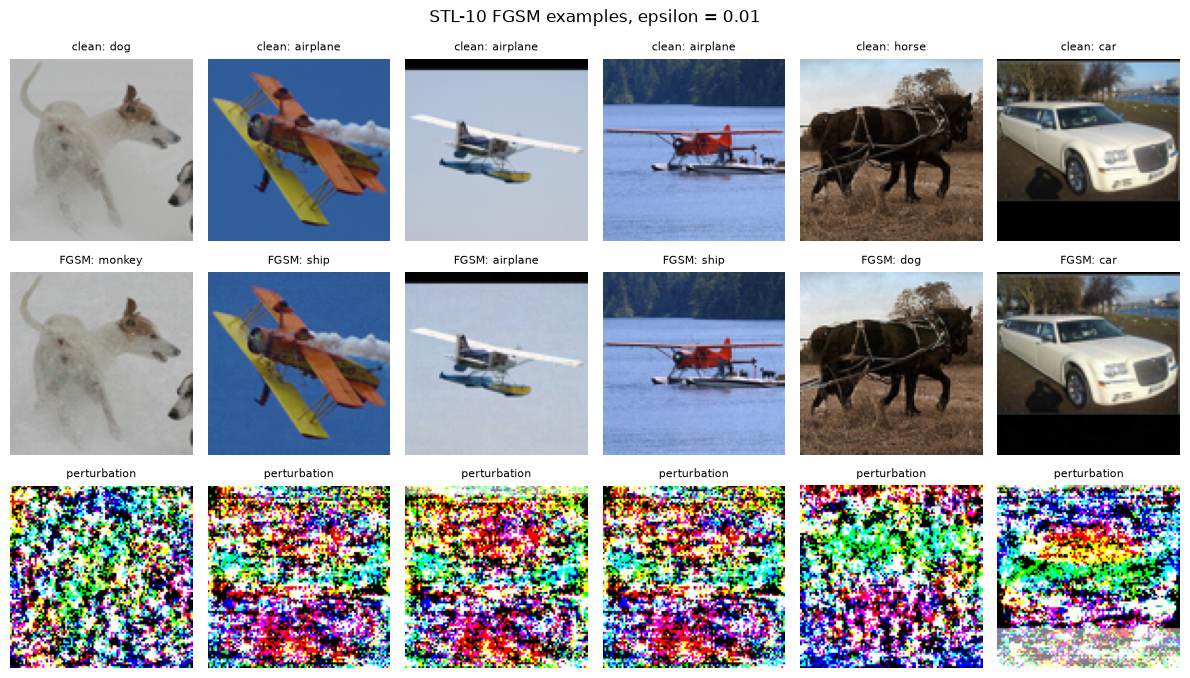

In [52]:
def show_stl_multiclass_adversarials(model, loader, epsilon, n=6):

    model.eval()

    # find correctly classified examples
    x_list = []
    y_list = []

    for x_batch, y_batch in loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        with torch.no_grad():
            pred = model(x_batch).argmax(1)

        correct = pred == y_batch

        x_list.append(x_batch[correct])
        y_list.append(y_batch[correct])

        # once we have n correct examples, stop searching
        if sum(len(x) for x in x_list) >= n:
            break

    x = torch.cat(x_list)[:n]
    y = torch.cat(y_list)[:n]

    # create adversarial examples
    x_adv = fgsm_attack(
        model,
        x,
        y,
        epsilon,
        F.cross_entropy
    )

    # predictions before and after FGSM
    with torch.no_grad():
        pred_clean = model(x).argmax(1).cpu()
        pred_adv = model(x_adv).argmax(1).cpu()

    class_names = stl_train.classes

    x = x.cpu()
    x_adv = x_adv.cpu()

    perturbation = x_adv - x

    fig, axes = plt.subplots(3, n, figsize=(2 * n, 7))

    for i in range(n):

        clean_img = x[i].permute(1, 2, 0)
        adv_img = x_adv[i].permute(1, 2, 0)

        # scale perturbation so it can be shown as RGB
        pert_img = ((perturbation[i] / epsilon) + 1) / 2
        pert_img = pert_img.permute(1, 2, 0).clamp(0, 1)

        axes[0, i].imshow(clean_img)
        axes[0, i].set_title(
            "clean: " + class_names[pred_clean[i].item()],
            fontsize=8
        )
        axes[0, i].axis("off")

        axes[1, i].imshow(adv_img)
        axes[1, i].set_title(
            "FGSM: " + class_names[pred_adv[i].item()],
            fontsize=8
        )
        axes[1, i].axis("off")

        axes[2, i].imshow(pert_img)
        axes[2, i].set_title("perturbation", fontsize=8)
        axes[2, i].axis("off")

    plt.suptitle("STL-10 FGSM examples, epsilon = " + str(epsilon))
    plt.tight_layout()
    plt.show()


show_stl_multiclass_adversarials(
    stl_mc_none,
    stl_test_loader,
    epsilon=0.01
)

## 4.5 Adversarial training

In [53]:
print("Training FGSM adversarial model (STL-10):")
stl_mc_adv = train(MulticlassLogReg(in_features=STL_DIM), stl_train_loader, binary=False, epochs=60, lr=0.0005, adv_epsilon=0.015, adv_weight=0.5)
clean_acc = evaluate_clean(stl_mc_adv, stl_test_loader, binary=False)
print("Clean test adversarial accuracy:", round(clean_acc, 4))

Training FGSM adversarial model (STL-10):
epoch 1 | loss: 2.6748 | train acc: 0.2144
epoch 5 | loss: 2.2899 | train acc: 0.342
epoch 10 | loss: 2.0842 | train acc: 0.4076
epoch 15 | loss: 1.985 | train acc: 0.4172
epoch 20 | loss: 1.9179 | train acc: 0.438
epoch 25 | loss: 1.91 | train acc: 0.4266
epoch 30 | loss: 1.8701 | train acc: 0.4378
epoch 35 | loss: 1.8849 | train acc: 0.4216
epoch 40 | loss: 1.8683 | train acc: 0.441
epoch 45 | loss: 1.8326 | train acc: 0.4534
epoch 50 | loss: 1.8795 | train acc: 0.4164
epoch 55 | loss: 1.8227 | train acc: 0.4608
epoch 60 | loss: 1.8037 | train acc: 0.4734
Clean test adversarial accuracy: 0.3483


In [54]:
# add adversarial training results
adv_accs = []

for eps in EPSILONS_STL:
    if eps == 0.0:
        acc = clean_acc
    else:
        acc = evaluate_fgsm(stl_mc_adv, stl_test_loader, eps, binary=False)

    adv_accs.append(acc)

results_stl_mc["adversarial training"] = adv_accs

# show results
print("epsilon:", *EPSILONS_STL)

for name, accs in results_stl_mc.items():
    print(name, *[round(a, 3) for a in accs])

epsilon: 0 0.002 0.005 0.01 0.015 0.02 0.025
no regularization 0.338 0.266 0.174 0.078 0.032 0.013 0.004
l2 0.34 0.258 0.159 0.075 0.03 0.011 0.005
l1 0.355 0.28 0.188 0.094 0.044 0.018 0.007
gaussian noise 0.338 0.339 0.338 0.339 0.338 0.338 0.338
random sign noise 0.338 0.339 0.338 0.338 0.337 0.338 0.338
adversarial training 0.348 0.314 0.269 0.196 0.142 0.1 0.069


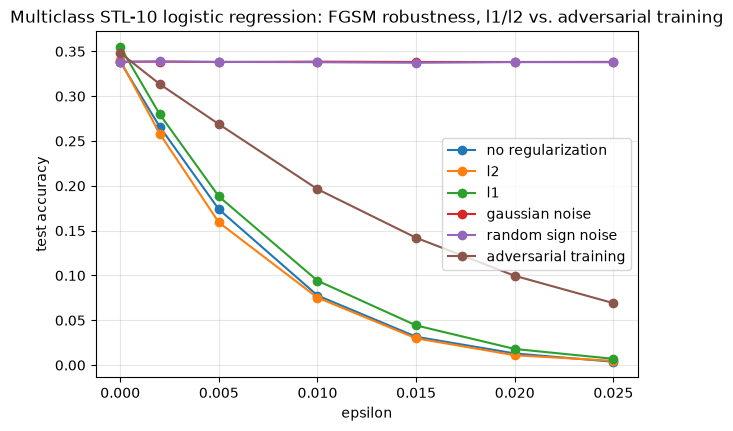

In [55]:
# re-plot with all four models together
plt.figure(figsize=(7, 4.5))
for name, accs in results_stl_mc.items():
    plt.plot(EPSILONS_STL, accs, marker="o", label=name)
plt.xlabel("epsilon")
plt.ylabel("test accuracy")
plt.title("Multiclass STL-10 logistic regression: FGSM robustness, l1/l2 vs. adversarial training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [56]:
# does adversarial training also shrink W_1, the way L1 does?
stl_mc_models_all = stl_mc_models + [("adversarial training", stl_mc_adv)]

rows = []

for name, model in stl_mc_models_all:
    W = model.linear.weight.detach().cpu().flatten()

    l1_norm = W.abs().sum().item()
    l2_norm = W.norm().item()
    inf_norm = W.abs().max().item()
    n_zero = (W.abs() < 1e-6).sum().item()

    rows.append({
        "model": name,
        "L1 norm": round(l1_norm, 2),
        "L2 norm": round(l2_norm, 2),
        "Inf norm": round(inf_norm, 4),
        "zeros": n_zero
    })

pd.DataFrame(rows)

,model,L1 norm,L2 norm,Inf norm,zeros
0,no regularization,1357.65,3.23,0.0329,46
1,l2,1355.83,3.23,0.0350,48
2,l1,1135.51,2.86,0.0329,143
3,adversarial training,525.61,1.52,0.0336,132


# Part 5 - Summary

## Save all the trained models and the results

In [57]:
# AI assistance: ChatGPT was used to check that this saving cell is consistent and includes all trained models.
import os

os.makedirs("saved_models", exist_ok=True)

models_to_save = {
    "model_none": model_none,
    "model_l2": model_l2,
    "model_l1": model_l1,
    "model_adv": model_adv,

    "mc_none": mc_none,
    "mc_l2": mc_l2,
    "mc_l1": mc_l1,
    "mc_adv": mc_adv,

    "stl_model_none": stl_model_none,
    "stl_model_l2": stl_model_l2,
    "stl_model_l1": stl_model_l1,
    "stl_model_adv": stl_model_adv,

    "stl_mc_none": stl_mc_none,
    "stl_mc_l2": stl_mc_l2,
    "stl_mc_l1": stl_mc_l1,
    "stl_mc_adv": stl_mc_adv
}

for name, model in models_to_save.items():
    torch.save(
        model.state_dict(),
        "saved_models/" + name + ".pt"
    )

print("Saved", len(models_to_save), "models to saved_models/")

Saved 16 models to saved_models/


In [58]:
import json

logreg_results = {
    "mnist_binary": {
        "epsilons": EPSILONS_MNIST,
        **results_bin
    },

    "mnist_multiclass": {
        "epsilons": EPSILONS_MNIST,
        **results_mc
    },

    "stl_binary": {
        "epsilons": EPSILONS_STL,
        **results_stl_bin
    },

    "stl_multiclass": {
        "epsilons": EPSILONS_STL,
        **results_stl_mc
    }
}

with open("logreg_results.json", "w") as f:
    json.dump(logreg_results, f, indent=2)

print("Saved logreg_results.json")

Saved logreg_results.json
